In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

orders = pd.DataFrame({
    "order_id": range(101, 113),
    "city": ["Lagos","Abuja","Lagos","Kano","Abuja","Lagos",
             "Kano","Abuja","Lagos","Kano","Abuja","Lagos"],
    "channel": ["Online","Store","Online","Store","Online","Store",
               "Online","Online","Store","Store","Online","Online"],
    "order_value": [2000,4000,3000,3500,5000,4500,
                    2500,3000,80000,4000,5500,3500],
    "delivery_days": [2,4,3,5,2,3,6,2,4,5,3,2],
    "age": [25,34,29,41,None,31,28,35,52,46,33,27]
})

print(orders[["delivery_days", "order_value"]].corr(method="pearson"))
print(orders[["delivery_days", "order_value"]].corr(method="spearman"))

               delivery_days  order_value
delivery_days       1.000000     0.127917
order_value         0.127917     1.000000
               delivery_days  order_value
delivery_days       1.000000     0.074162
order_value         0.074162     1.000000


In [4]:
import pandas as pd

In [5]:
import matplotlib.pyplot as plt

In [6]:
import seaborn as sns

In [7]:
sns.set_theme(style= "whitegrid")

In [8]:
orders = pd.DataFrame({
    "order_id": range(101, 113),
    "city": ["Lagos","Abuja","Lagos","Kano","Abuja","Lagos",
             "Kano","Abuja","Lagos","Kano","Abuja","Lagos"],
    "channel": ["Online","Store","Online","Store","Online","Store",
               "Online","Online","Store","Store","Online","Online"],
    "order_value": [2000,4000,3000,3500,5000,4500,
                    2500,3000,80000,4000,5500,3500],
    "delivery_days": [2,4,3,5,2,3,6,2,4,5,3,2],
    "age": [25,34,29,41,None,31,28,35,52,46,33,27]
})

print(orders.shape)
print(orders.head())

(12, 6)
   order_id   city channel  order_value  delivery_days   age
0       101  Lagos  Online         2000              2  25.0
1       102  Abuja   Store         4000              4  34.0
2       103  Lagos  Online         3000              3  29.0
3       104   Kano   Store         3500              5  41.0
4       105  Abuja  Online         5000              2   NaN


In [9]:
print(orders.isna().sum())
print(orders["city"].value_counts(dropna=False))


order_id         0
city             0
channel          0
order_value      0
delivery_days    0
age              1
dtype: int64
city
Lagos    5
Abuja    4
Kano     3
Name: count, dtype: int64


In [10]:
x = orders["order_value"]
print(x.mean())
print(x.median())

10041.666666666666
3750.0


In [11]:
print(x.sort_values().tolist())

[2000, 2500, 3000, 3000, 3500, 3500, 4000, 4000, 4500, 5000, 5500, 80000]


In [12]:
print(x.mean())
print(x[x < 80000].mean())

10041.666666666666
3681.818181818182


In [1]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(data=orders, x="order_value", bins=8, ax=ax)
ax.set(title="Order value distribution - fictional retail orders",
       xlabel="Order value (NGN)", ylabel="Number of orders")
plt.tight_layout()
plt.show()


NameError: name 'plt' is not defined

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

orders = pd.DataFrame({
    "order_id": range(101, 113),
    "city": ["Lagos","Abuja","Lagos","Kano","Abuja","Lagos",
             "Kano","Abuja","Lagos","Kano","Abuja","Lagos"],
    "channel": ["Online","Store","Online","Store","Online","Store",
               "Online","Online","Store","Store","Online","Online"],
    "order_value": [2000,4000,3000,3500,5000,4500,
                    2500,3000,80000,4000,5500,3500],
    "delivery_days": [2,4,3,5,2,3,6,2,4,5,3,2],
    "age": [25,34,29,41,None,31,28,35,52,46,33,27]
})

x = orders["order_value"]
print(orders.shape)

(12, 6)


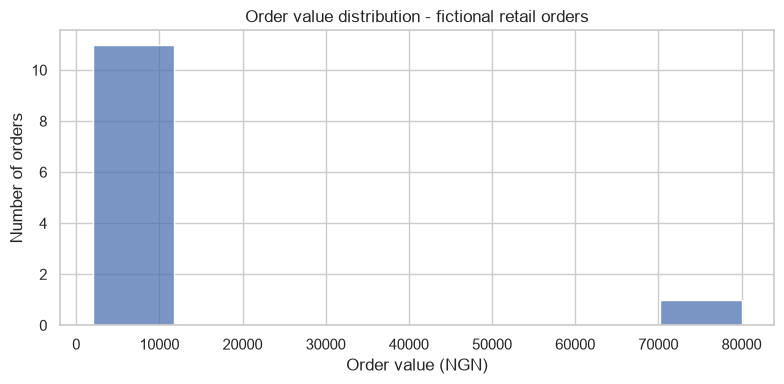

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(data=orders, x="order_value", bins=8, ax=ax)
ax.set(title="Order value distribution - fictional retail orders",
       xlabel="Order value (NGN)", ylabel="Number of orders")
plt.tight_layout()
plt.show()

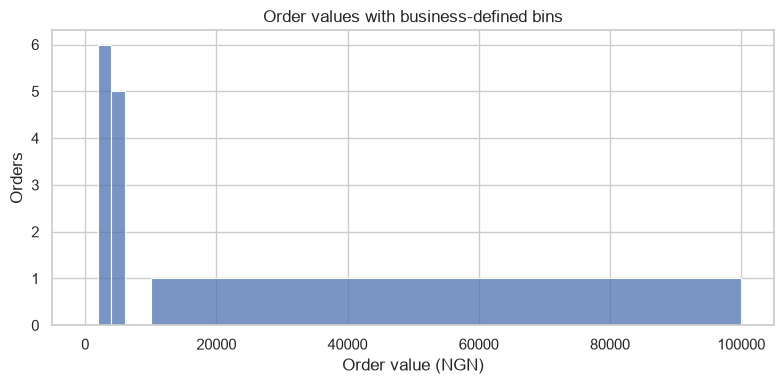

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(data=orders, x="order_value", bins=[0, 2000, 4000, 6000, 10000, 100000], ax=ax)
ax.set(title="Order values with business-defined bins",
       xlabel="Order value (NGN)", ylabel="Orders")
plt.tight_layout()
plt.show()

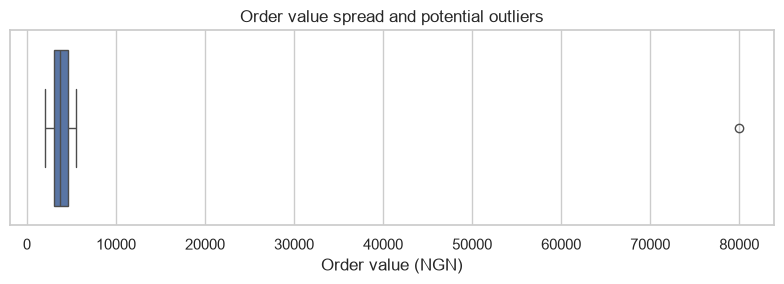

In [5]:
fig, ax = plt.subplots(figsize=(8, 3))
sns.boxplot(data=orders, x="order_value", ax=ax)
ax.set(title="Order value spread and potential outliers",
       xlabel="Order value (NGN)")
plt.tight_layout()
plt.show()

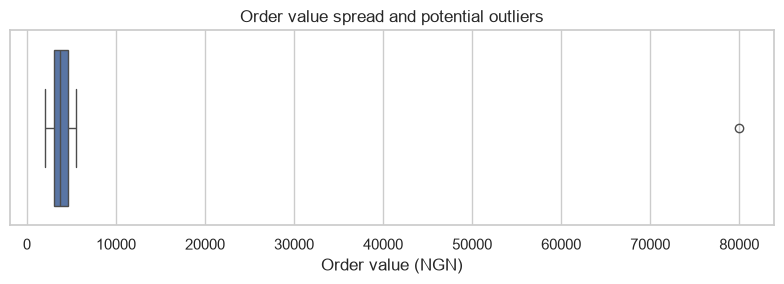

In [6]:
fig, ax = plt.subplots(figsize=(8, 3))
sns.boxplot(data=orders, x="order_value", ax=ax)
ax.set(title="Order value spread and potential outliers",
       xlabel="Order value (NGN)")
plt.tight_layout()
plt.show()

In [7]:
q1, q3 = orders["order_value"].quantile([.25, .75])
iqr = q3 - q1
upper = q3 + 1.5 * iqr
print(q1, q3, iqr, upper)

3000.0 4625.0 1625.0 7062.5


In [8]:
x = orders["order_value"]
q1, q3 = x.quantile([.25, .75])
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

flagged = orders.loc[(x < lower) | (x > upper)]
print("lower cutoff:", lower)
print("upper cutoff:", upper)
print(flagged[["order_id", "order_value"]])

lower cutoff: 562.5
upper cutoff: 7062.5
   order_id  order_value
8       109        80000


In [9]:
print("Mean all:", orders["order_value"].mean())
print("Mean without flagged:", orders.loc[~orders.index.isin(flagged.index), "order_value"].mean())
print("Median all:", orders["order_value"].median())
print("Median without flagged:", orders.loc[~orders.index.isin(flagged.index), "order_value"].median())

Mean all: 10041.666666666666
Mean without flagged: 3681.818181818182
Median all: 3750.0
Median without flagged: 3500.0


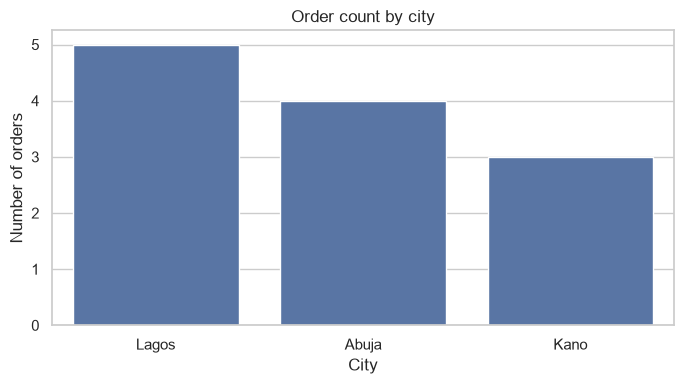

In [10]:
counts = orders["city"].value_counts().rename_axis("city").reset_index(name="orders")
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=counts, x="city", y="orders", ax=ax)
ax.set(title="Order count by city", xlabel="City", ylabel="Number of orders")
ax.set_ylim(bottom=0)
plt.tight_layout()
plt.show()

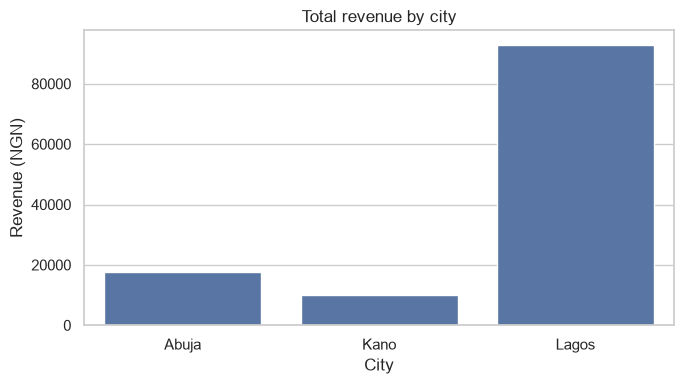

    city  order_value
0  Abuja        17500
1   Kano        10000
2  Lagos        93000


In [11]:
revenue = orders.groupby("city", as_index=False)["order_value"].sum()
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=revenue, x="city", y="order_value", ax=ax)
ax.set(title="Total revenue by city", xlabel="City", ylabel="Revenue (NGN)")
ax.set_ylim(bottom=0)
plt.tight_layout()
plt.show()
print(revenue)

In [12]:
print(orders.groupby("city")["order_value"].agg(["count", "mean", "median"]))



       count          mean  median
city                              
Abuja      4   4375.000000  4500.0
Kano       3   3333.333333  3500.0
Lagos      5  18600.000000  3500.0


In [13]:
print(orders.groupby("city")["order_value"].agg(["count", "mean", "median"]))

       count          mean  median
city                              
Abuja      4   4375.000000  4500.0
Kano       3   3333.333333  3500.0
Lagos      5  18600.000000  3500.0


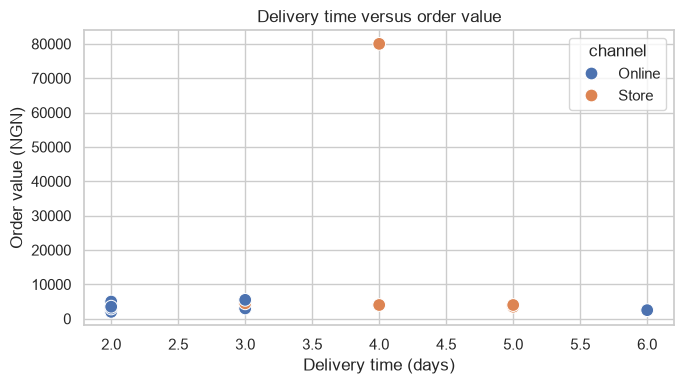

In [14]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.scatterplot(data=orders, x="delivery_days", y="order_value", hue="channel", s=85, ax=ax)
ax.set(title="Delivery time versus order value",
       xlabel="Delivery time (days)", ylabel="Order value (NGN)")
plt.tight_layout()
plt.show()


In [3]:
print(orders[["delivery_days", "order_value"]].corr(method="pearson"))
print(orders[["delivery_days", "order_value"]].corr(method="spearman"))

               delivery_days  order_value
delivery_days       1.000000     0.127917
order_value         0.127917     1.000000
               delivery_days  order_value
delivery_days       1.000000     0.074162
order_value         0.074162     1.000000


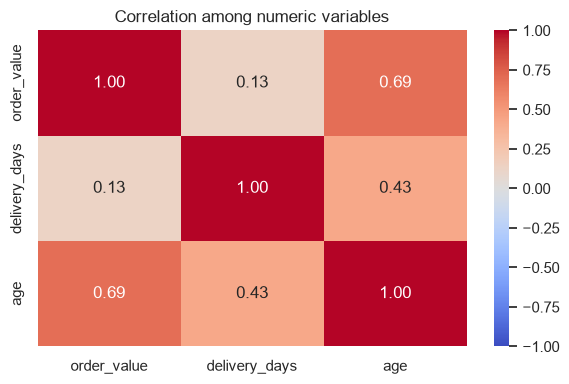

In [4]:
numeric = orders[["order_value", "delivery_days", "age"]]
corr = numeric.corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(6, 4))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, center=0, ax=ax)
ax.set(title="Correlation among numeric variables")
plt.tight_layout()
plt.show()

In [5]:
ages = orders.dropna(subset=["age"])
print(len(ages))
print(ages[["age", "order_value"]].corr(method="pearson"))
print(ages[["age", "order_value"]].corr(method="spearman"))

11
                  age  order_value
age          1.000000     0.692503
order_value  0.692503     1.000000
                  age  order_value
age          1.000000     0.613287
order_value  0.613287     1.000000


In [6]:
ages = orders.dropna(subset=["age"])
print(len(ages))
print(ages[["age", "order_value"]].corr(method="pearson"))
print(ages[["age", "order_value"]].corr(method="spearman"))

11
                  age  order_value
age          1.000000     0.692503
order_value  0.692503     1.000000
                  age  order_value
age          1.000000     0.613287
order_value  0.613287     1.000000


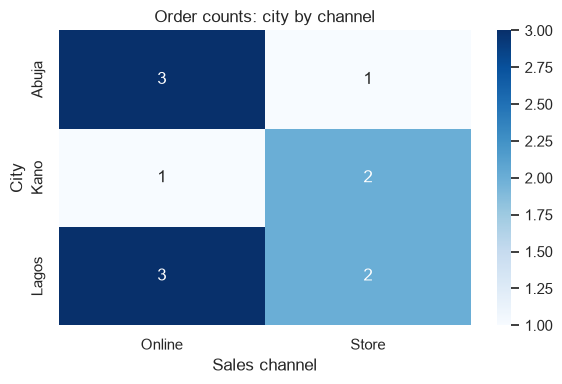

In [7]:
cross = pd.crosstab(orders["city"], orders["channel"])

fig, ax = plt.subplots(figsize=(6, 4))
sns.heatmap(cross, annot=True, fmt="d", cmap="Blues", ax=ax)
ax.set(title="Order counts: city by channel", xlabel="Sales channel", ylabel="City")
plt.tight_layout()
plt.show()


In [8]:
pct = pd.crosstab(orders["city"], orders["channel"], normalize="index").mul(100)
print(pct.round(1))

channel  Online  Store
city                  
Abuja      75.0   25.0
Kano       33.3   66.7
Lagos      60.0   40.0


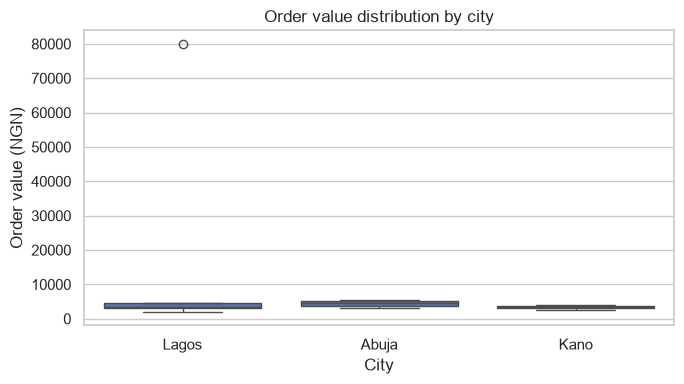

In [9]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(data=orders, x="city", y="order_value", ax=ax)
ax.set(title="Order value distribution by city",
       xlabel="City", ylabel="Order value (NGN)")
plt.tight_layout()
plt.show()